In [1]:
# MINI PROJECT: Handwritten Digit Classifier

# STEP 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [2]:
# STEP 2: Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


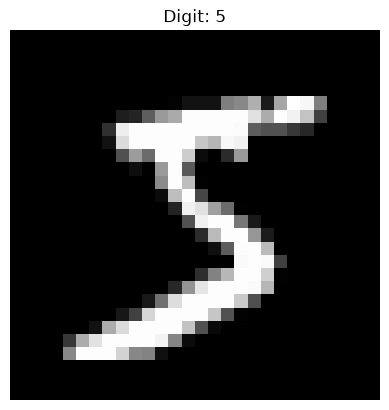

In [3]:
# STEP 3: Display one handwritten digit
plt.imshow(X_train[0], cmap="gray")
plt.title("Digit: " + str(y_train[0]))
plt.axis("off")
plt.show()

In [4]:
# STEP 4: Normalize pixel values
# Convert values from 0-255 into 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

In [6]:
# STEP 5: Create the neural network
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])


In [7]:
# STEP 6: Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
# STEP 7: Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9220 - loss: 0.2760 - val_accuracy: 0.9645 - val_loss: 0.1238
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9640 - loss: 0.1218 - val_accuracy: 0.9717 - val_loss: 0.1058
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9744 - loss: 0.0832 - val_accuracy: 0.9768 - val_loss: 0.0874
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9809 - loss: 0.0619 - val_accuracy: 0.9773 - val_loss: 0.0769
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9849 - loss: 0.0477 - val_accuracy: 0.9788 - val_loss: 0.0756


In [9]:
# STEP 8: Test the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9763 - loss: 0.0785

Test Accuracy: 97.63 %
Test Loss: 0.0785


In [10]:
# STEP 9: Predict digits
predictions = model.predict(X_test)
predicted_digits = np.argmax(predictions, axis=1)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


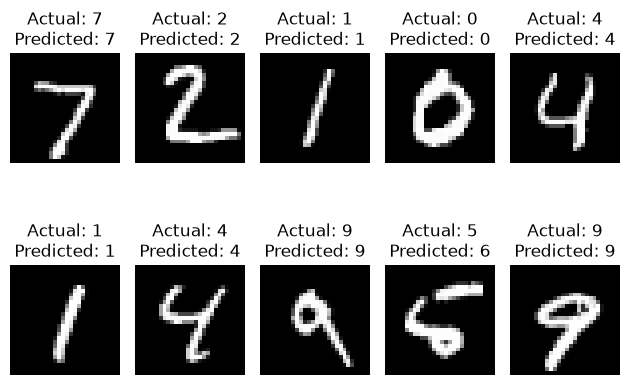

In [11]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(predicted_digits[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# STEP 11: Calculate accuracy, precision and recall
print("\nAccuracy:", round(
    accuracy_score(y_test, predicted_digits), 4))

print("Precision:", round(
    precision_score(y_test, predicted_digits, average="macro"), 4))

print("Recall:", round(
    recall_score(y_test, predicted_digits, average="macro"), 4))


Accuracy: 0.9763
Precision: 0.9763
Recall: 0.9762


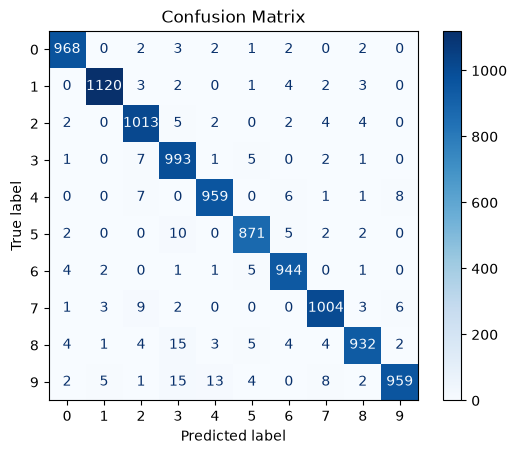

In [13]:
# STEP 12: Display confusion matrix
cm = confusion_matrix(y_test, predicted_digits)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [14]:
# STEP 13: Find five incorrect predictions
wrong = np.where(predicted_digits != y_test)[0]

print("\nFive Incorrect Predictions:")

for i in wrong[:5]:
    print("Actual:", y_test[i],
          "| Predicted:", predicted_digits[i])


Five Incorrect Predictions:
Actual: 5 | Predicted: 6
Actual: 9 | Predicted: 3
Actual: 4 | Predicted: 2
Actual: 3 | Predicted: 5
Actual: 2 | Predicted: 7


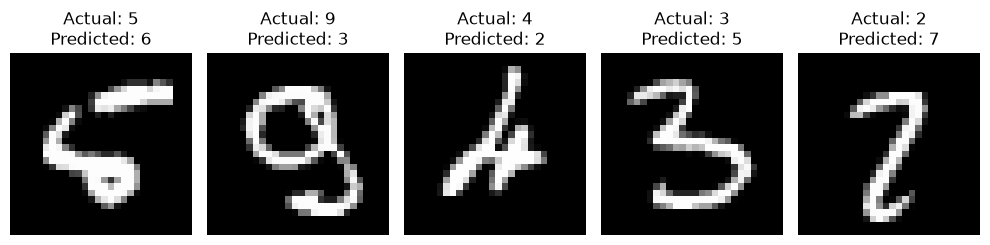

In [15]:
# STEP 14: Display the five incorrect predictions
plt.figure(figsize=(10, 4))

for j in range(min(5, len(wrong))):
    i = wrong[j]

    plt.subplot(1, 5, j + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(predicted_digits[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 15: Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
# STEP 16: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
# STEP 17: Error analysis
print("\nERROR ANALYSIS")
print("1. Some handwritten digits look similar.")
print("2. Some digits may be unclear or poorly written.")
print("3. Different writing styles can confuse the model.")
print("4. The neural network may not learn every pattern.")
print("5. More training or model tuning may improve results.")
